# MicroGrad: Scalar Autograd Engine

## 1. Introduction

This notebook demonstrates a scalar automatic differentiation engine and a Multi-Layer Perceptron implemented from scratch.

### Objectives
- Understand computational graphs.
- Understand automatic differentiation.
- Implement and explore backpropagation.
- Understand neural network training.
- Apply gradient descent.
- Visualize model behavior.

import sys
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Locate the project root
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.engine import Value
from src.nn import MLP

# Reproducibility
random.seed(42)
np.random.seed(42)

print("MicroGrad environment initialized successfully!")

In [1]:
import sys
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Locate the project root
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.engine import Value
from src.nn import MLP

# Reproducibility
random.seed(42)
np.random.seed(42)

print("MicroGrad environment initialized successfully!")

Matplotlib is building the font cache; this may take a moment.


MicroGrad environment initialized successfully!


In [2]:
# Create two variables
a = Value(2.0)
b = Value(3.0)

# Perform mathematical operations
c = a * b + a

# Calculate gradients
c.backward()

# Display results
print("Value of a:", a.data)
print("Value of b:", b.data)
print("Value of c:", c.data)

print("\nGradients:")
print("dc/da =", a.grad)
print("dc/db =", b.grad)

Value of a: 2.0
Value of b: 3.0
Value of c: 8.0

Gradients:
dc/da = 4.0
dc/db = 2.0


In [3]:
c.backward()

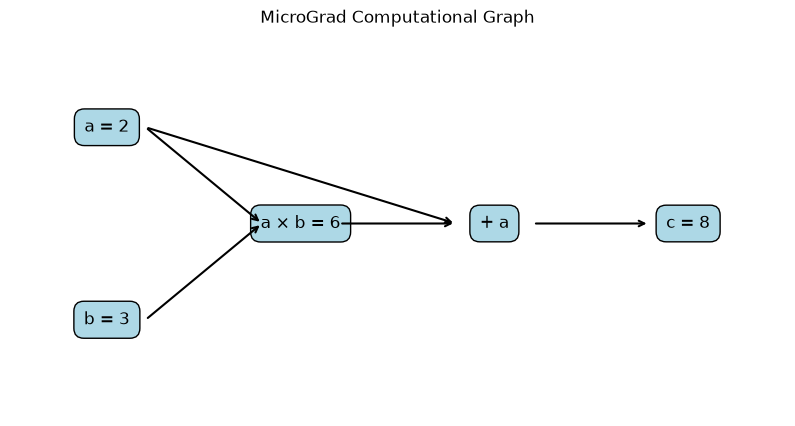

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

# Define node positions
positions = {
    "a": (0, 2),
    "b": (0, 0),
    "mul": (2, 1),
    "add": (4, 1),
    "c": (6, 1)
}

# Define node labels
labels = {
    "a": "a = 2",
    "b": "b = 3",
    "mul": "a × b = 6",
    "add": "+ a",
    "c": "c = 8"
}

# Draw nodes
for node, (x, y) in positions.items():
    ax.text(
        x, y, labels[node],
        ha="center", va="center",
        fontsize=12,
        bbox=dict(boxstyle="round,pad=0.6", fc="lightblue")
    )

# Connect the nodes
edges = [
    ("a", "mul"),
    ("b", "mul"),
    ("mul", "add"),
    ("a", "add"),
    ("add", "c")
]

for start, end in edges:
    x1, y1 = positions[start]
    x2, y2 = positions[end]

    ax.annotate(
        "",
        xy=(x2 - 0.4, y2),
        xytext=(x1 + 0.4, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

ax.set_xlim(-1, 7)
ax.set_ylim(-1, 3)
ax.axis("off")
ax.set_title("MicroGrad Computational Graph")

plt.show()

## 3. Activation Functions

Activation functions introduce non-linearity into neural networks.

In MicroGrad, we explore two important operations:

- tanh(): Hyperbolic tangent activation function.
- exp(): Exponential function.

In [5]:
# Test the tanh activation function

x = Value(0.5)
y = x.tanh()

y.backward()

print("Input:", x.data)
print("Tanh output:", y.data)
print("Gradient:", x.grad)

Input: 0.5
Tanh output: 0.46211715726000974
Gradient: 0.7864477329659274


In [6]:
# Test the exponential function

x = Value(1.0)
y = x.exp()

y.backward()

print("Input:", x.data)
print("Exp output:", y.data)
print("Gradient:", x.grad)

Input: 1.0
Exp output: 2.718281828459045
Gradient: 2.718281828459045


## 4. Multi-Layer Perceptron (MLP)

A Multi-Layer Perceptron is a feedforward neural network consisting of interconnected layers of neurons.

In this section, we will:
- Create an MLP.
- Pass input data through the network.
- Observe the network predictions.
- Count the trainable parameters.

In [7]:
# Create a neural network
model = MLP(3, [4, 4, 1])

# Input data
x = [2.0, 3.0, -1.0]

# Forward pass
prediction = model(x)

print("Network prediction:", prediction.data)
print("Number of parameters:", len(model.parameters()))

Network prediction: 0.6994093620224068
Number of parameters: 41


## 5. Loss Function and Backpropagation

A loss function measures the difference between a model's prediction and the target value.

Backpropagation calculates gradients of the loss with respect to the model parameters.

In [8]:
# Define a target value
target = Value(1.0)

# Reset gradients
model.zero_grad()

# Forward pass
prediction = model(x)

# Calculate squared error loss
loss = (prediction - target) ** 2

# Backpropagation
loss.backward()

print("Prediction:", prediction.data)
print("Target:", target.data)
print("Loss:", loss.data)

print("\nExample parameter gradients:")
for i, p in enumerate(model.parameters()[:5]):
    print(f"Parameter {i+1}: gradient = {p.grad}")

Prediction: 0.6994093620224068
Target: 1.0
Loss: 0.0903547316397765

Example parameter gradients:
Parameter 1: gradient = 0.011079398745261523
Parameter 2: gradient = 0.016619098117892285
Parameter 3: gradient = -0.005539699372630762
Parameter 4: gradient = 0.005539699372630762
Parameter 5: gradient = 0.2968430817776005


## 6. Training with Gradient Descent

Gradient descent is an optimization algorithm used to minimize the loss function.

It updates the neural network parameters using their gradients.

The update rule is:

parameter = parameter - learning_rate × gradient


In [9]:
# Training configuration
learning_rate = 0.05
epochs = 100

target = 1.0
loss_history = []

# Training loop
for epoch in range(epochs):

    # Forward pass
    prediction = model(x)

    # Calculate loss
    loss = (prediction - target) ** 2

    # Reset gradients
    model.zero_grad()

    # Backpropagation
    loss.backward()

    # Update parameters
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    loss_history.append(loss.data)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Loss = {loss.data:.6f}"
        )

print("\nFinal prediction:", model(x).data)

Epoch 10: Loss = 0.016393
Epoch 20: Loss = 0.009418
Epoch 30: Loss = 0.006793
Epoch 40: Loss = 0.005374
Epoch 50: Loss = 0.004472
Epoch 60: Loss = 0.003843
Epoch 70: Loss = 0.003377
Epoch 80: Loss = 0.003017
Epoch 90: Loss = 0.002729
Epoch 100: Loss = 0.002493

Final prediction: 0.9502808386031616


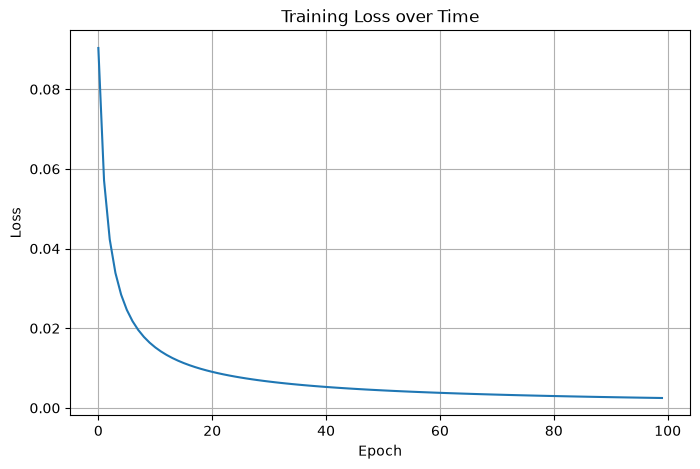

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Time")

plt.grid(True)
plt.show()

In [11]:
# Evaluate the trained model

final_prediction = model(x)
final_loss = (final_prediction - target) ** 2

print("Target:", target)
print("Final prediction:", final_prediction.data)
print("Final loss:", final_loss.data)
print("Absolute error:", abs(final_prediction.data - target))

Target: 1.0
Final prediction: 0.9502808386031616
Final loss: 0.0024719950100048666
Absolute error: 0.04971916139683841


## 7. Training Results and Evaluation

The neural network was trained using gradient descent for 100 epochs.

The training loss decreased over time, demonstrating that the network successfully learned to minimize the prediction error.

### Observations
- Backpropagation calculated gradients for the network parameters.
- Gradient descent updated the parameters.
- The loss decreased throughout training.
- The final prediction moved closer to the target value.

### Conclusion

This experiment demonstrates how automatic differentiation, backpropagation, and gradient descent work together to train a neural network.